In [97]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings

df = pd.read_csv("../data/raw/MFG10YearTerminationData.csv")

In [98]:
df.shape

(49653, 18)

In [99]:
df.head()

,EmployeeID,recorddate_key,birthdate_key,orighiredate_key,terminationdate_key,age,length_of_service,city_name,department_name,job_title,store_name,gender_short,gender_full,termreason_desc,termtype_desc,STATUS_YEAR,STATUS,BUSINESS_UNIT
0,1318,12/31/2006 0:00,1954-01-03,1989-08-28,1900-01-01,52,17,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2006,ACTIVE,HEADOFFICE
1,1318,12/31/2007 0:00,1954-01-03,1989-08-28,1900-01-01,53,18,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2007,ACTIVE,HEADOFFICE
2,1318,12/31/2008 0:00,1954-01-03,1989-08-28,1900-01-01,54,19,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2008,ACTIVE,HEADOFFICE
3,1318,12/31/2009 0:00,1954-01-03,1989-08-28,1900-01-01,55,20,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2009,ACTIVE,HEADOFFICE
4,1318,12/31/2010 0:00,1954-01-03,1989-08-28,1900-01-01,56,21,Vancouver,Executive,CEO,35,M,Male,Not Applicable,Not Applicable,2010,ACTIVE,HEADOFFICE


In [100]:
'''
EmployeeID:çalışanın benzersiz kimliği
recorddate_key:kaydın ait olduğu tarih
birthdate_key:çalışanın doğum tarihi
orighiredate_key:çalışanın işe giriş tarihi
terminationdate_key:çalışanın işten ayrılma tarihi
age:çalışanın yaşı
length_of_service:çalışanın şirkette çalışma süresi
city_name:kayıttaki şehrin adı
department_name:çalışanın çalıştığı departman
job_title:çalışanın iş unvanı
store_name:çalıştığı mağazanın adı
gender_short:cinsiyetin kısa kodu
gender_full:cinsiyetin uzun kodu
termreason_desc:ayrılma sebebi
termtype_desc:ayrılma türü
STATUS_YEAR: kaydın ait olduğu yıl
STATUS: o yılki çalışan durumu
BUSINESS_UNIT: çalışanın çalıştığı iş birimi
'''

'\nEmployeeID:çalışanın benzersiz kimliği\nrecorddate_key:kaydın ait olduğu tarih\nbirthdate_key:çalışanın doğum tarihi\norighiredate_key:çalışanın işe giriş tarihi\nterminationdate_key:çalışanın işten ayrılma tarihi\nage:çalışanın yaşı\nlength_of_service:çalışanın şirkette çalışma süresi\ncity_name:kayıttaki şehrin adı\ndepartment_name:çalışanın çalıştığı departman\njob_title:çalışanın iş unvanı\nstore_name:çalıştığı mağazanın adı\ngender_short:cinsiyetin kısa kodu\ngender_full:cinsiyetin uzun kodu\ntermreason_desc:ayrılma sebebi\ntermtype_desc:ayrılma türü\nSTATUS_YEAR: kaydın ait olduğu yıl\nSTATUS: o yılki çalışan durumu\nBUSINESS_UNIT: çalışanın çalıştığı iş birimi\n'

In [101]:
print("Benzersiz çalışan sayısı:", df['EmployeeID'].nunique())

Benzersiz çalışan sayısı: 6284


In [102]:
print("İlk yıl:", df["STATUS_YEAR"].min())
print("Son yıl:", df["STATUS_YEAR"].max())
#veri seti hangi yılları kapsıyor
#toplam 10 yıllık çalışan kayıtları var.

İlk yıl: 2006
Son yıl: 2015


In [103]:
df.dtypes

EmployeeID              int64
recorddate_key         object
birthdate_key          object
orighiredate_key       object
terminationdate_key    object
age                     int64
length_of_service       int64
city_name              object
department_name        object
job_title              object
store_name              int64
gender_short           object
gender_full            object
termreason_desc        object
termtype_desc          object
STATUS_YEAR             int64
STATUS                 object
BUSINESS_UNIT          object
dtype: object

In [104]:
df.isna().sum()
#nan hücre yok

EmployeeID             0
recorddate_key         0
birthdate_key          0
orighiredate_key       0
terminationdate_key    0
age                    0
length_of_service      0
city_name              0
department_name        0
job_title              0
store_name             0
gender_short           0
gender_full            0
termreason_desc        0
termtype_desc          0
STATUS_YEAR            0
STATUS                 0
BUSINESS_UNIT          0
dtype: int64

In [105]:
df.describe()

,EmployeeID,age,length_of_service,store_name,STATUS_YEAR
count,49653.000000,49653.000000,49653.000000,49653.000000,49653.000000
mean,4859.495740,42.077035,10.434596,27.297605,2010.612612
std,1826.571142,12.427257,6.325286,13.514134,2.845577
min,1318.000000,19.000000,0.000000,1.000000,2006.000000
25%,3360.000000,31.000000,5.000000,16.000000,2008.000000
50%,5031.000000,42.000000,10.000000,28.000000,2011.000000
75%,6335.000000,53.000000,15.000000,42.000000,2013.000000
max,8336.000000,65.000000,26.000000,46.000000,2015.000000


In [106]:
df["STATUS"].value_counts() 

STATUS
ACTIVE        48168
TERMINATED     1485
Name: count, dtype: int64

In [107]:
df.loc[df["STATUS"] == "TERMINATED", "EmployeeID"].nunique()
#aynı çalışanın birden fazla ayrılma kaydı olabilir mi diye kontrol ediyoruz

1485

In [108]:
df.loc[
    df["STATUS"] == "TERMINATED",
    "termreason_desc"
].value_counts()
#çalışanların ayrılma sebeplerinin dağılımını kontrol ediyoruz
#885 emeklilik 
#385 istifa
#215 işten çıkarılma

termreason_desc
Retirement    885
Resignaton    385
Layoff        215
Name: count, dtype: int64

In [109]:
df.loc[
    df["STATUS"] == "TERMINATED",
    "termtype_desc"
].value_counts()
#kaç çalışanın gönüllü kaçının gönülsüz ayrıldığını kontrol ediyoruz

termtype_desc
Voluntary      1270
Involuntary     215
Name: count, dtype: int64

In [110]:
df.duplicated().sum()
#tekrarlayan kayıt yok - 0

np.int64(0)

In [111]:
df.duplicated(subset=["EmployeeID", "STATUS_YEAR"]).sum()

np.int64(5)

In [112]:
df.loc[
    df.duplicated(subset=["EmployeeID", "STATUS_YEAR"], keep=False)
].sort_values(["EmployeeID", "STATUS_YEAR"])
#aynı yıl içinde hem active hem de ayrılmış olduğu için aynı çalışan var

,EmployeeID,recorddate_key,birthdate_key,orighiredate_key,terminationdate_key,age,length_of_service,city_name,department_name,job_title,store_name,gender_short,gender_full,termreason_desc,termtype_desc,STATUS_YEAR,STATUS,BUSINESS_UNIT
9679,3008,12/31/2007 0:00,1942-12-31,1994-07-08,2007-12-31,65,13,Vancouver,Dairy,Dairy Person,35,F,Female,Retirement,Voluntary,2007,ACTIVE,STORES
49258,3008,12/1/2007 0:00,1942-12-31,1994-07-08,2007-12-31,65,13,Vancouver,Dairy,Dairy Person,35,F,Female,Retirement,Voluntary,2007,TERMINATED,STORES
12167,3401,12/31/2008 0:00,1943-12-31,1995-07-08,2008-12-31,65,13,Victoria,Meats,Meat Cutter,37,F,Female,Retirement,Voluntary,2008,ACTIVE,STORES
49475,3401,12/1/2008 0:00,1943-12-31,1995-07-08,2008-12-31,65,13,Victoria,Meats,Meat Cutter,37,F,Female,Retirement,Voluntary,2008,TERMINATED,STORES
41843,7007,12/31/2009 0:00,1984-11-08,2008-08-02,2009-12-31,25,1,Cranbrook,Processed Foods,Shelf Stocker,8,F,Female,Resignaton,Voluntary,2009,ACTIVE,STORES
48299,7007,12/1/2009 0:00,1984-11-08,2008-08-02,2009-12-31,25,1,Cranbrook,Processed Foods,Shelf Stocker,8,F,Female,Resignaton,Voluntary,2009,TERMINATED,STORES
41966,7023,12/31/2014 0:00,1984-12-31,2008-08-30,2014-12-31,30,6,Kelowna,Processed Foods,Shelf Stocker,16,F,Female,Resignaton,Voluntary,2014,ACTIVE,STORES
48528,7023,12/1/2014 0:00,1984-12-31,2008-08-30,2014-12-31,30,6,Kelowna,Processed Foods,Shelf Stocker,16,F,Female,Resignaton,Voluntary,2014,TERMINATED,STORES
48049,8296,12/31/2013 0:00,1994-09-02,2013-10-09,2013-12-31,19,0,Kelowna,Customer Service,Cashier,16,F,Female,Resignaton,Voluntary,2013,ACTIVE,STORES
48553,8296,12/1/2013 0:00,1994-09-02,2013-10-09,2013-12-31,19,0,Kelowna,Customer Service,Cashier,16,F,Female,Resignaton,Voluntary,2013,TERMINATED,STORES


In [113]:
employee_left = (
    df["STATUS"].eq("TERMINATED")
    .groupby(df["EmployeeID"])
    .any()
)

employee_left.value_counts()
#1485 çalışan ayrılmış
#4799 çalışan ayrılmamış

STATUS
False    4799
True     1485
Name: count, dtype: int64

In [114]:
active_ids = set(df.loc[df["STATUS"] == "ACTIVE", "EmployeeID"])
terminated_ids = set(df.loc[df["STATUS"] == "TERMINATED", "EmployeeID"])

len(active_ids & terminated_ids)
#1339 kişi hem terminated hem de active olarak gözüküyor. 
#1485-1339=146 kişi sadece terminated olarak gözüküyor.


1339

In [115]:
#Sadece terminated kaydı olanların işe giriş ve ayrılma tarihlerinin incelenmesi
only_terminated_ids = terminated_ids - active_ids

df.loc[
    df["EmployeeID"].isin(only_terminated_ids),
    [
        "EmployeeID", "orighiredate_key",
        "terminationdate_key", "STATUS_YEAR", "length_of_service"
    ]
].head(10)

,EmployeeID,orighiredate_key,terminationdate_key,STATUS_YEAR,length_of_service
48170,4347,1998-03-31,2006-09-23,2006,8
48177,7801,2011-09-23,2011-10-23,2011,0
48178,2479,1993-01-16,2006-07-11,2006,13
48181,2598,1993-05-30,2006-11-22,2006,13
48194,4215,1997-11-08,2006-05-03,2006,8
48198,4346,1998-03-29,2006-09-21,2006,8
48217,4149,1997-08-31,2006-02-23,2006,8
48225,2478,1993-01-16,2006-07-11,2006,13
48254,7416,2010-04-08,2010-09-25,2010,0
48261,2332,1992-08-21,2006-02-14,2006,13


In [116]:
only_terminated_ids = terminated_ids - active_ids

records = df.loc[
    df["EmployeeID"].isin(only_terminated_ids)
    & df["STATUS"].eq("TERMINATED")
].copy()

exit_dates = pd.to_datetime(records["terminationdate_key"])
year_end_mask = exit_dates.dt.month.eq(12) & exit_dates.dt.day.eq(31)

print(
    "31 Aralık'ta ayrılan çalışan sayısı:",
    records.loc[year_end_mask, "EmployeeID"].nunique()
)

records.loc[
    year_end_mask,
    ["EmployeeID", "orighiredate_key", "terminationdate_key", "STATUS_YEAR"]
]

31 Aralık'ta ayrılan çalışan sayısı: 0


,EmployeeID,orighiredate_key,terminationdate_key,STATUS_YEAR


In [117]:
hire_year = pd.to_datetime(records["orighiredate_key"]).dt.year
exit_year = pd.to_datetime(records["terminationdate_key"]).dt.year

print("2006'da ayrılan:", records.loc[exit_year.eq(2006), "EmployeeID"].nunique())
print("Girdiği yıl ayrılan:", records.loc[hire_year.eq(exit_year), "EmployeeID"].nunique())

2006'da ayrılan: 134
Girdiği yıl ayrılan: 13


In [118]:
#toplam departman sayısı
df["department_name"].nunique()


21

In [119]:
#hangi departmanda kaç kişi ayrılmış
departures = df[df["STATUS"] == "TERMINATED"]

departures.groupby("department_name")["EmployeeID"].nunique().sort_values(
    ascending=False
)


department_name
Meats                     377
Produce                   353
Customer Service          262
Dairy                     191
Bakery                    112
Processed Foods            90
Store Management           31
HR Technology               9
Recruitment                 8
Labor Relations             6
Employee Records            6
Accounting                  6
Training                    5
Information Technology      5
Accounts Receiveable        5
Accounts Payable            4
Audit                       4
Compensation                4
Investment                  4
Legal                       3
Name: EmployeeID, dtype: int64

In [120]:
#ayrılan çalışanlar ile toplam çalışanların oranını hesaplıyoruz
total = df.groupby("department_name")["EmployeeID"].nunique()

left = departures.groupby("department_name")["EmployeeID"].nunique()

rate = (left / total * 100).fillna(0)
#hiç ayrılma kaydı olmayan departmanlar için 0 yüzdelik değer atıyoruz
rate.sort_values(ascending=False)

summary = pd.DataFrame({
    "Toplam çalışan": total,
    "Ayrılan çalışan": left,
    "Ayrılma yüzdesi": rate
})

summary.fillna(0).round(2)

,Toplam çalışan,Ayrılan çalışan,Ayrılma yüzdesi
department_name,,,
Accounting,6,6.0,100.00
Accounts Payable,4,4.0,100.00
Accounts Receiveable,5,5.0,100.00
Audit,4,4.0,100.00
Bakery,898,112.0,12.47
Compensation,4,4.0,100.00
Customer Service,1190,262.0,22.02
Dairy,1033,191.0,18.49
Employee Records,6,6.0,100.00


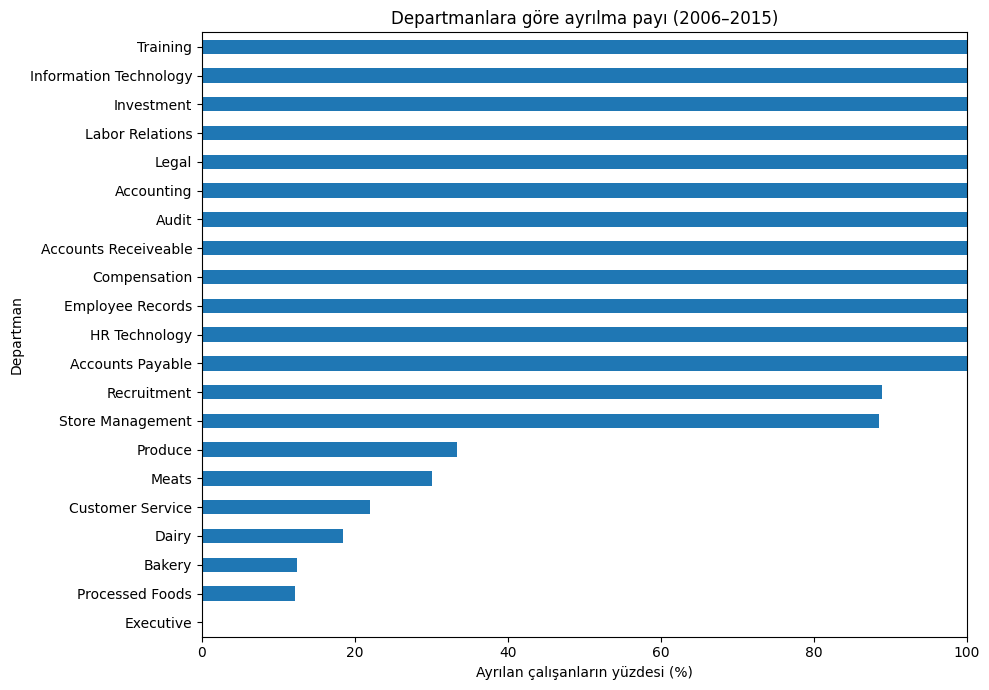

In [121]:
rate.sort_values().plot.barh(figsize=(10, 7))

plt.title("Departmanlara göre ayrılma payı (2006–2015)")
plt.xlabel("Ayrılan çalışanların yüzdesi (%)")
plt.ylabel("Departman")
plt.xlim(0, 100)
plt.tight_layout()#boşlukları otomatik ayarlıyor
plt.show()

In [122]:
department_year = pd.crosstab(
    departures["department_name"],
    departures["STATUS_YEAR"]
)

department_year

STATUS_YEAR,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
department_name,,,,,,,,,,
Accounting,0,0,0,0,0,0,0,0,1,5
Accounts Payable,0,0,0,0,1,0,0,0,1,2
Accounts Receiveable,0,0,0,0,2,0,0,0,1,2
Audit,0,0,0,1,2,0,0,0,0,1
Bakery,6,6,16,5,14,6,13,15,22,9
Compensation,0,0,0,1,2,0,0,0,0,1
Customer Service,3,2,6,4,10,40,40,21,98,38
Dairy,20,25,19,17,13,13,12,13,29,30
Employee Records,0,0,0,2,0,0,0,0,4,0


In [123]:
pd.crosstab(
    departures["department_name"],
    departures["termreason_desc"]
)
#layoff:işverenin işten çıkarma
#resignation:çalışanın kendi isteğiyle ayrılması
#retirement:çalışanın emekli olması

termreason_desc,Layoff,Resignaton,Retirement
department_name,,,
Accounting,0,0,6
Accounts Payable,0,0,4
Accounts Receiveable,0,0,5
Audit,0,0,4
Bakery,21,30,61
Compensation,0,0,4
Customer Service,70,179,13
Dairy,46,64,81
Employee Records,0,0,6


In [124]:
#departmanlardaki çalışan sayısı ile işten çıkarılma sayısını karşılaştırıyoruz
total = df.groupby("department_name")["EmployeeID"].nunique()

layoffs = departures[departures["termreason_desc"] == "Layoff"]

layoff_count = layoffs.groupby("department_name")["EmployeeID"].nunique()

layoff_rate = (layoff_count / total * 100).fillna(0)

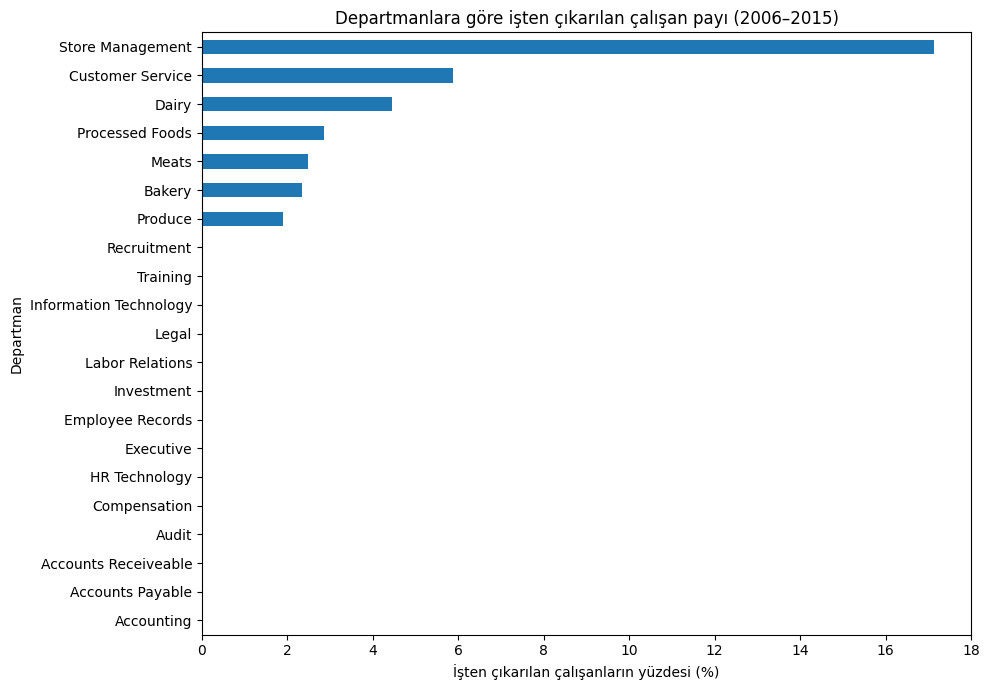

In [125]:
layoff_rate.sort_values().plot.barh(figsize=(10, 7))

plt.title("Departmanlara göre işten çıkarılan çalışan payı (2006–2015)")
plt.xlabel("İşten çıkarılan çalışanların yüzdesi (%)")
plt.ylabel("Departman")
plt.tight_layout()
plt.show()

In [126]:
#ayrılanlar ortalama kaç yıl çalışmış
departures.groupby("termreason_desc")["length_of_service"].mean().round(2)

termreason_desc
Layoff        11.95
Resignaton     4.64
Retirement    14.15
Name: length_of_service, dtype: float64

In [127]:
total_gender = df.groupby("gender_full")["EmployeeID"].nunique()

left_gender = departures.groupby("gender_full")["EmployeeID"].nunique()

gender_rate = left_gender / total_gender * 100

gender_rate

gender_full
Female    27.913362
Male      18.962076
Name: EmployeeID, dtype: float64

In [128]:
pd.crosstab( #iki sütunu karşılaştırıyoruz,eşleşenleri alıyoruz
    departures["gender_full"],
    departures["termreason_desc"]
)

termreason_desc,Layoff,Resignaton,Retirement
gender_full,,,
Female,113,211,591
Male,102,174,294


In [129]:
#İstifa edenleri, 
#kendi cinsiyet grubundaki toplam çalışan sayısına bölelim:
resignations = departures[departures["termreason_desc"] == "Resignaton"]

resigned_gender = resignations.groupby("gender_full")["EmployeeID"].nunique()

resignation_rate = resigned_gender / total_gender * 100

resignation_rate.round(2)

gender_full
Female    6.44
Male      5.79
Name: EmployeeID, dtype: float64

In [130]:
#ayrılma sebeplerine göre yaş ortalaması
departures.groupby("termreason_desc")["age"].mean().round(2)

termreason_desc
Layoff        40.80
Resignaton    30.10
Retirement    63.34
Name: age, dtype: float64

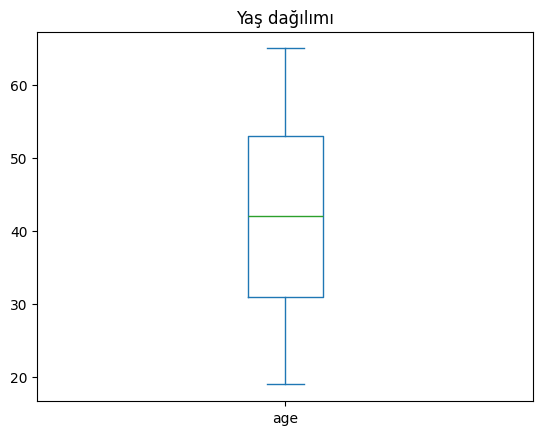

In [131]:
df["age"].plot.box()
plt.title("Yaş dağılımı")
plt.show()

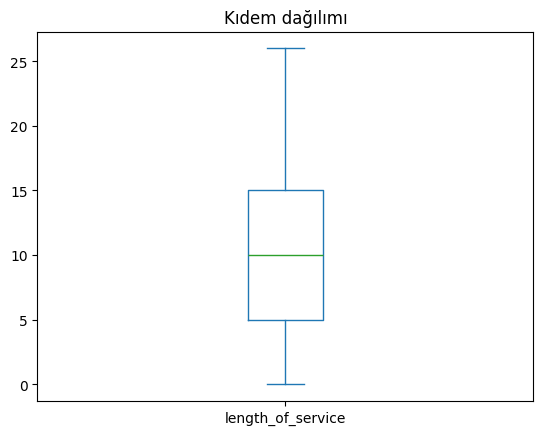

In [132]:
df["length_of_service"].plot.box()
plt.title("Kıdem dağılımı")
plt.show()

In [133]:
#istifa eden çalışanlar şirkette kaç yıl çalışmış
resignations = departures[departures["termreason_desc"] == "Resignaton"]

resignations["length_of_service"].value_counts().sort_index()

length_of_service
0      31
1     132
2      16
3      12
4      18
5      51
6      39
7       8
8      13
9       7
10     13
11      7
12      2
13      6
14      7
15      6
16      2
17      8
18      2
19      1
20      2
21      1
22      1
Name: count, dtype: int64

In [134]:
#şehirlere göre ayrılma sayısı
departures.groupby("city_name")["EmployeeID"].nunique().sort_values(
    ascending=False
)

city_name
Vancouver           296
Victoria            151
Nanaimo              82
New Westminster      70
Kamloops             61
Kelowna              59
Prince George        55
Fort Nelson          47
Surrey               44
New Westminister     44
Terrace              41
Burnaby              34
Cranbrook            33
Grand Forks          33
Chilliwack           32
Quesnel              31
White Rock           28
Richmond             28
Fort St John         28
Langley              27
Trail                26
Haney                24
Squamish             22
West Vancouver       22
Vernon               22
Princeton            19
Abbotsford           18
Dawson Creek         18
Port Coquitlam       15
North Vancouver      12
Aldergrove           11
Williams Lake        10
Pitt Meadows          9
Nelson                7
Ocean Falls           7
Cortes Island         6
Valemount             5
Bella Bella           5
Dease Lake            2
Blue River            1
Name: EmployeeID, dtype: int64

In [135]:
#"New Westminster", "New Westminister" iki şehrin aynı kayıt mı olup olmadıklarına bakıyoruz
count=departures.loc[
    departures["city_name"].isin(["New Westminster", "New Westminister"]),
    "EmployeeID"
].nunique()

print("İki şehir yazımındaki ayrılan çalışan sayısı:", count)

İki şehir yazımındaki ayrılan çalışan sayısı: 114


In [136]:
#şehirde geçen mağaza bilgilerini kontrol ediyoruz
df.loc[
    df["city_name"].isin(["New Westminster", "New Westminister"]),
    ["city_name", "store_name"]
].drop_duplicates()

,city_name,store_name
444,New Westminster,21
3081,New Westminister,20


In [137]:
#ortak çalışan olup olmadığını kontrol ediyoruz
city1_ids = set(
    df.loc[df["city_name"] == "New Westminster", "EmployeeID"]
)

city2_ids = set(
    df.loc[df["city_name"] == "New Westminister", "EmployeeID"]
)

common_ids = city1_ids & city2_ids

print("İki yazımda da bulunan çalışan sayısı:", len(common_ids))
#NOT: "New Westminster" ve "New Westminister" iki farklı yazım şekliyle aynı şehri temsil ediyor gibi görünüyor.
#ama aynı şehir olup olmadııklarını yaptığımız analizler sonucu kesin olarak çıkaramadık. Bu nedenle, bu iki şehri birleştirmeden analizlerimizi yapacağız.

İki yazımda da bulunan çalışan sayısı: 0
